# Finding care you can trust: a look at the data

**CMU Datathon, Fall 2026 · Hruday Nara**

The challenge asked a simple question: a health worker needs a specific kind of care for a patient, so where should they go, and why should they believe the answer?

The dataset behind it is about 10,000 Indian health facilities scraped from the web. Before building anything, I wanted to understand what the data could and couldn't tell us. This notebook walks through what I found, roughly in the order I found it.

**How to read this:** every number comes straight from the project's data files or from `reports/findings.json`. Nothing is typed in by hand. To rerun it, open the notebook from the repo root with the *Python (CMU Datathon .venv)* kernel.

In [1]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd()/'data').exists() else Path.cwd().parent
D = ROOT/'data'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
fac = pd.read_parquet(D/'silver/facilities.parquet')
g3 = pd.read_parquet(D/'gold/capability_grades_v03.parquet')
flags = pd.read_parquet(D/'gold/facility_flags.parquet')
F = json.load(open(ROOT/'reports/findings.json'))
items = F['findings'] if isinstance(F, dict) and 'findings' in F else F
FV = {x['key']: x.get('value') for x in items}
print(len(fac), 'facilities;', len(g3), 'grade rows;', len(flags), 'flag rows')

9989 facilities; 119868 grade rows; 3654 flag rows


---

## Part 1: What's in the data

### Who is actually in this table?

The first thing that jumped out is how lopsided the table is. Most records are private facilities that have some kind of web presence. Government hospitals, which carry a huge share of India's actual care, barely show up.

That matters for everything after this. When the tool later says *"no reliable option nearby,"* it often really means *"nothing nearby in this data,"* and the app says so out loud.

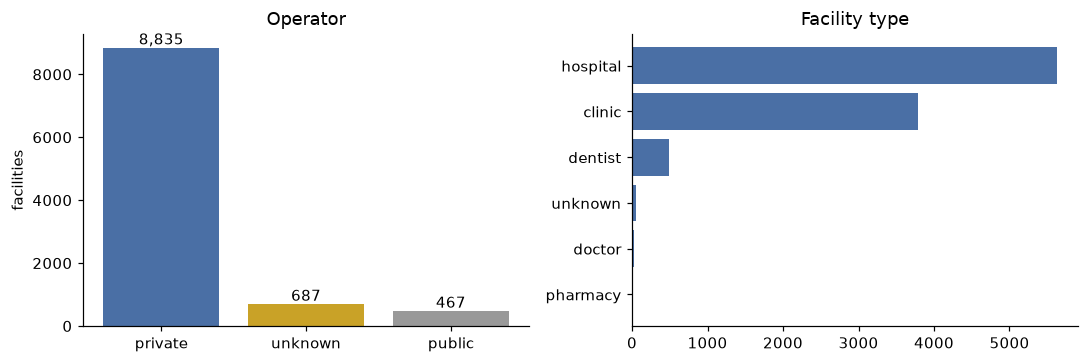

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
op = fac.operator_type.fillna('unknown').value_counts()
ax[0].bar(op.index, op.values, color=['#4a6fa5','#c9a227','#999'][:len(op)])
ax[0].set_title('Operator'); ax[0].set_ylabel('facilities')
for i, v in enumerate(op.values): ax[0].text(i, v, f'{v:,}', ha='center', va='bottom')
ft = fac.facility_type.fillna('unknown').value_counts().head(6)
ax[1].barh(ft.index[::-1], ft.values[::-1], color='#4a6fa5'); ax[1].set_title('Facility type')
plt.tight_layout(); plt.show()

---

## Part 2: Claims versus evidence

### Saying you do something isn't the same as doing it

Every facility lists specialties, but a specialty label is just a claim. So I sorted each facility, for each of the 12 services, into three levels:

- **Claimed:** only a specialty label, like "nephrology".
- **Supported:** at least one sentence in its record actually names the service, like "provides haemodialysis".
- **Corroborated:** the service *plus* the things it depends on, for example a C-section and a blood bank. These rules follow published standards (WHO, FBNC, PM-JAY, PMNDP).

**What to notice:** for almost every service, the grey "claimed only" bar dwarfs the green ones. Only the green bars can ever be recommended by the tool.

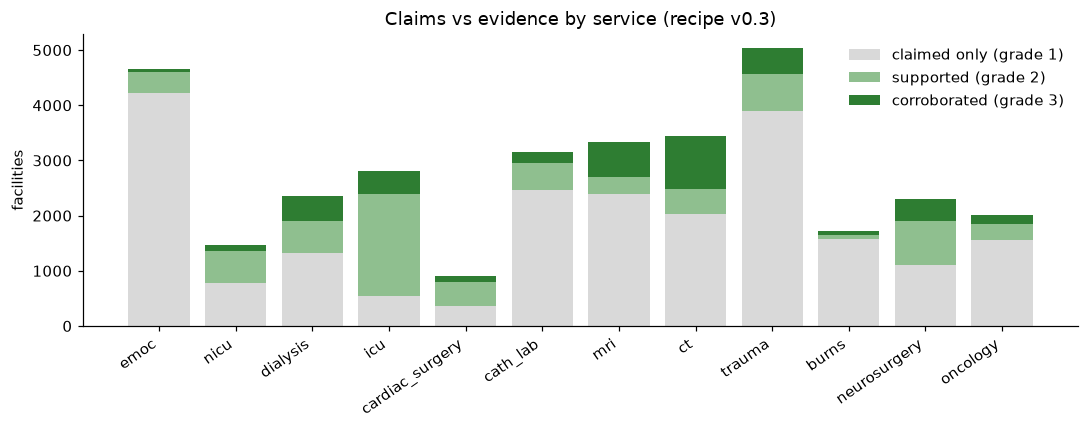

service_line
emoc               0.09
nicu               0.47
dialysis           0.44
icu                0.81
cardiac_surgery    0.61
cath_lab           0.22
mri                0.28
ct                 0.41
trauma             0.22
burns              0.08
neurosurgery       0.52
oncology           0.22
Name: share of claimers with evidence, dtype: float64


In [3]:
order = ['emoc','nicu','dialysis','icu','cardiac_surgery','cath_lab','mri','ct','trauma','burns','neurosurgery','oncology']
ct = g3.pivot_table(index='service_line', columns='grade', values='facility_id', aggfunc='count').reindex(order).fillna(0)
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(order)); b = np.zeros(len(order))
for gr, col, lab in [(1,'#d9d9d9','claimed only (grade 1)'), (2,'#8fbf8f','supported (grade 2)'), (3,'#2e7d32','corroborated (grade 3)')]:
    v = ct.get(gr, pd.Series(0, index=order)).values
    ax.bar(x, v, bottom=b, color=col, label=lab); b += v
ax.set_xticks(x); ax.set_xticklabels(order, rotation=35, ha='right'); ax.set_ylabel('facilities')
ax.set_title('Claims vs evidence by service (recipe v0.3)'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
print((ct[[2,3]].sum(axis=1) / ct[[1,2,3]].sum(axis=1)).round(2).rename('share of claimers with evidence'))

### The headline gap: emergency C-sections

This is the single chart that convinced me the obvious approach ("filter by specialty, sort by distance") would hand out confident wrong answers.

Thousands of records list obstetrics. Only a small fraction have a sentence that actually names a caesarean, and fewer still mention the maternal blood supply the operation depends on.

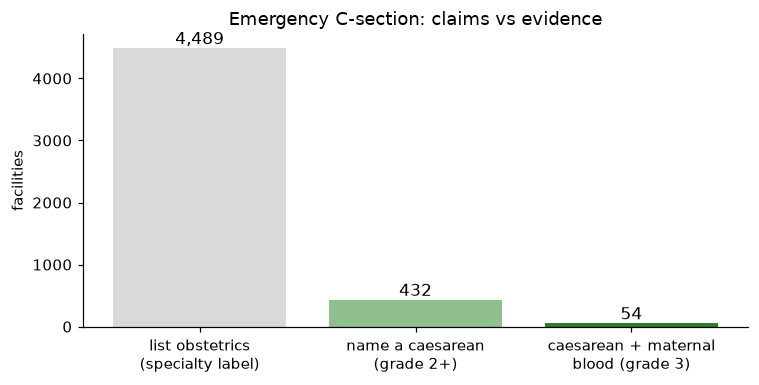

In [4]:
obs = fac.specialties.apply(lambda s: 'gynecologyAndObstetrics' in list(s)).sum()
e = g3[g3.service_line=='emoc']
n2 = int((e.grade>=2).sum()); n3 = int((e.grade==3).sum())
vals = [obs, n2, n3]; labs = ['list obstetrics\n(specialty label)', 'name a caesarean\n(grade 2+)', 'caesarean + maternal\nblood (grade 3)']
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(labs, vals, color=['#d9d9d9','#8fbf8f','#2e7d32'])
for i, v in enumerate(vals): ax.text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=11)
ax.set_ylabel('facilities'); ax.set_title('Emergency C-section: claims vs evidence')
plt.tight_layout(); plt.show()

### Where the evidence is

Each grey dot is a facility with a usable location. The green ones have a record that actually names a caesarean.

**What to notice:** the evidence clusters around big cities. Large stretches of the country have plenty of facilities that *claim* obstetric care but none whose record shows it, which is exactly where a confident wrong answer costs a patient the most time.

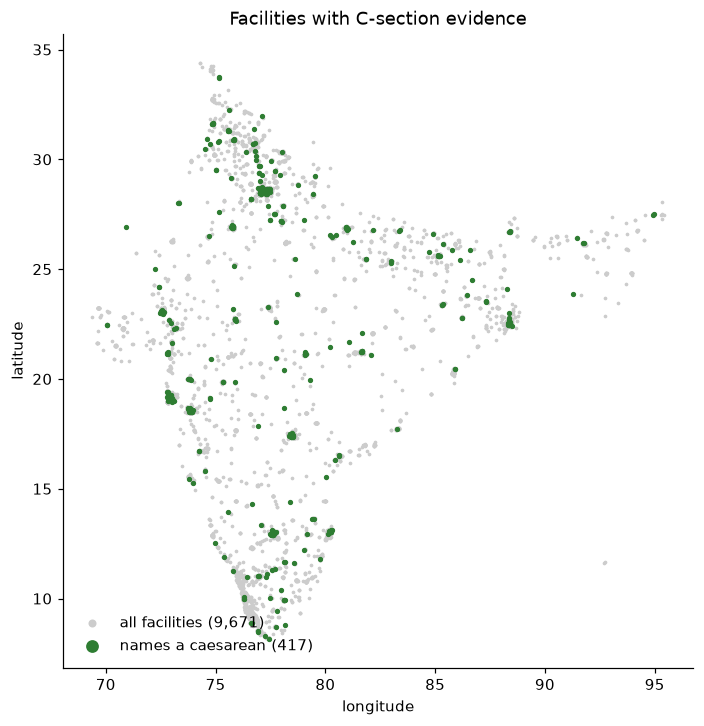

In [5]:
ok = fac[fac.lat.notna()]
ids = set(e[e.grade>=2].facility_id)
fig, ax = plt.subplots(figsize=(6.5, 7))
ax.scatter(ok.lon, ok.lat, s=2, c='#cccccc', label=f'all facilities ({len(ok):,})')
k = ok[ok.facility_id.isin(ids)]
ax.scatter(k.lon, k.lat, s=6, c='#2e7d32', label=f'names a caesarean ({len(k):,})')
ax.set_aspect('equal'); ax.set_xlabel('longitude'); ax.set_ylabel('latitude')
ax.set_title('Facilities with C-section evidence'); ax.legend(frameon=False, loc='lower left', markerscale=3)
plt.tight_layout(); plt.show()

---

## Part 3: Can we trust the records themselves?

### Trust checks

Even when a record names a service, the record itself can be wrong. While reading the data I kept running into three problems:

- **Possible merges:** one record that mixes up several branches or hospitals.
- **Location conflicts:** coordinates that are nowhere near the facility's own PIN code.
- **Implausible claims:** for example a small clinic claiming heart surgery.

A *major* flag blocks a facility from being recommended for that service. A *minor* one just shows up as a warning on its card.

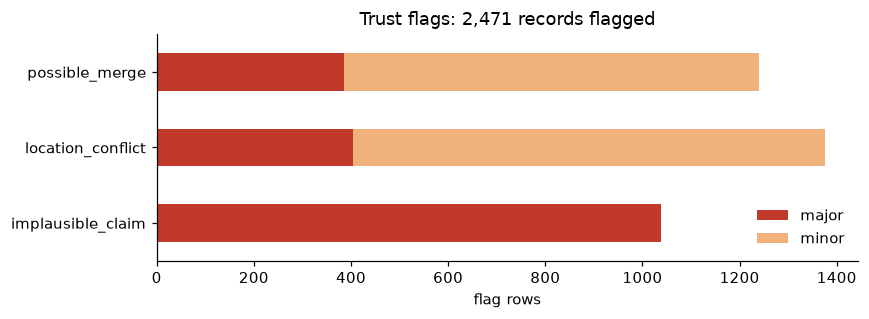

In [6]:
fc = flags.groupby(['flag','severity']).size().unstack(fill_value=0)
fc.plot(kind='barh', stacked=True, color={'major':'#c0392b','minor':'#f0b27a'}, figsize=(8, 3))
plt.title(f'Trust flags: {flags.facility_id.nunique():,} records flagged'); plt.xlabel('flag rows'); plt.ylabel('')
plt.legend(frameon=False); plt.tight_layout(); plt.show()

---

## Part 4: The models

### Teaching a small model to read the records

The records contain about 275,000 distinct sentences, so I needed something to tag each one with the services it mentions. I tried three approaches:

1. **Hand-written rules** (regular expressions).
2. **Claude as a "teacher"**, labeling about 29,000 sentences for under a dollar.
3. **A small, fast "student" model** trained on the teacher's labels, which runs on everything in seconds, for free, with no API calls.

**What to notice:** the shipped version only uses the student on tags where it *provably* beat the rules, so it ends up a little ahead of everything else. The gain is real but modest, and I'd rather say that than oversell it. (The gold set was labeled by an AI agent, not a clinician.)

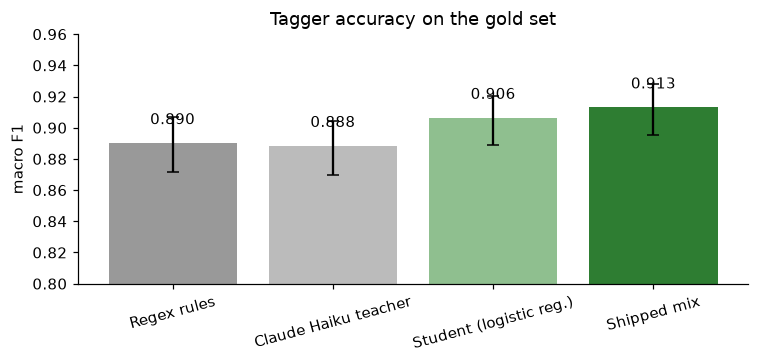

In [7]:
names = [('regex','Regex rules'), ('teacher','Claude Haiku teacher'), ('student_1b','Student (logistic reg.)'), ('shipped','Shipped mix')]
v = [FV[f'tagger.{k}.macro_f1'] for k, _ in names]
lo = [FV[f'tagger.{k}.macro_f1'] - FV[f'tagger.{k}.macro_f1_ci_low'] for k, _ in names]
hi = [FV[f'tagger.{k}.macro_f1_ci_high'] - FV[f'tagger.{k}.macro_f1'] for k, _ in names]
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar([n for _, n in names], v, yerr=[lo, hi], capsize=4, color=['#999','#bbb','#8fbf8f','#2e7d32'])
for i, x in enumerate(v): ax.text(i, x + 0.012, f'{x:.3f}', ha='center')
ax.set_ylim(0.8, 0.96); ax.set_ylabel('macro F1'); ax.set_title('Tagger accuracy on the gold set')
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

### Turning distance into drive time

Straight-line distance is misleading in India: roads wind, and hill states are much slower. So I fitted a simple model to 934 real road-routed trips: **minutes ≈ 2.30 × km^0.842**, adjusted by a terrain factor for each state.

**What to notice:** most real trips fall inside the dashed band. It's an estimate at free-flow speed, not a promise, and the app labels it that way.

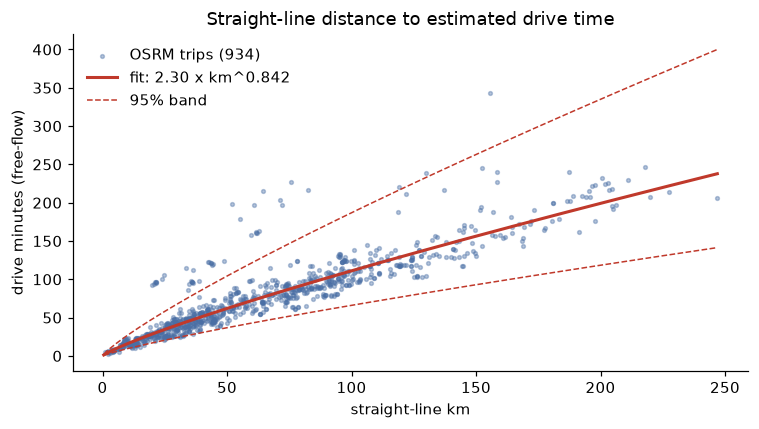

In [8]:
tr = pd.read_csv(D/'external/score_research/osrm_pairs.csv')
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(tr.km, tr.osrm_min, s=6, alpha=0.4, c='#4a6fa5', label=f'OSRM trips ({len(tr):,})')
xs = np.linspace(0.5, tr.km.max(), 200)
ax.plot(xs, 2.30*xs**0.842, c='#c0392b', lw=2, label='fit: 2.30 x km^0.842')
ax.plot(xs, 2.30*xs**0.842*np.exp(0.52), c='#c0392b', lw=1, ls='--', label='95% band')
ax.plot(xs, 2.30*xs**0.842*np.exp(-0.52), c='#c0392b', lw=1, ls='--')
ax.set_xlabel('straight-line km'); ax.set_ylabel('drive minutes (free-flow)'); ax.legend(frameon=False)
ax.set_title('Straight-line distance to estimated drive time'); plt.tight_layout(); plt.show()

---

## Part 5: Does it actually work?

### The sealed evaluation

To avoid grading my own homework, I fixed the test in advance and ran it exactly once: 140 searches at 60 random post offices across India. Three tools answered each one:

- **Specialty filter:** the obvious approach.
- **Nearest record naming the service:** a simple evidence-based rule.
- **Our ranker:** evidence, trust checks, and drive time.

Independent AI judges then read each top pick's record and asked: *does this record clearly show the facility offers the service?*

**What to notice:** the obvious approach is right only about one time in five. Both evidence-based tools do far better. Ours comes out slightly ahead of the simple rule, but that difference isn't statistically significant, and I say so.

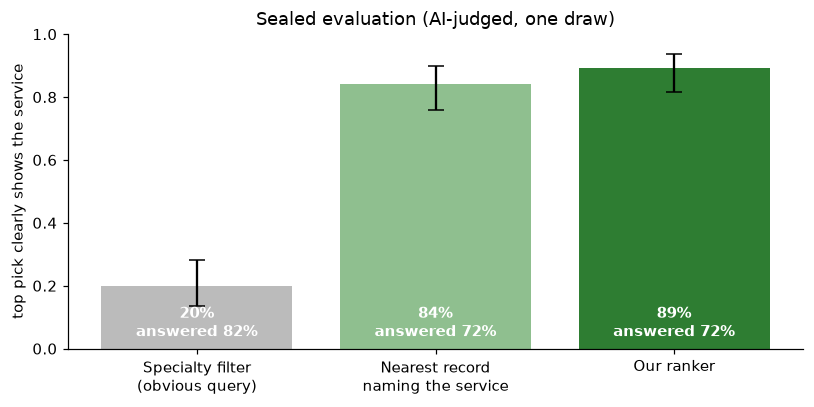

Ranker vs nearest-record-naming-it: not significantly different (p = 0.125); both far above the specialty filter.


In [9]:
tools = [('specialty','Specialty filter\n(obvious query)'), ('any_fact','Nearest record\nnaming the service'), ('ranker','Our ranker')]
p = [FV[f'sealed_eval.sealed.{t}.precision.rate'] for t, _ in tools]
lo = [p[i] - FV[f'sealed_eval.sealed.{t}.precision.ci_low'] for i, (t, _) in enumerate(tools)]
hi = [FV[f'sealed_eval.sealed.{t}.precision.ci_high'] - p[i] for i, (t, _) in enumerate(tools)]
cov = [FV[f'sealed_eval.sealed.{t}.coverage.rate'] for t, _ in tools]
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.bar([n for _, n in tools], p, yerr=[lo, hi], capsize=5, color=['#bbb','#8fbf8f','#2e7d32'])
for i, (x, c) in enumerate(zip(p, cov)): ax.text(i, 0.04, f'{x:.0%}\nanswered {c:.0%}', ha='center', color='white', fontweight='bold')
ax.set_ylim(0, 1); ax.set_ylabel('top pick clearly shows the service')
ax.set_title('Sealed evaluation (AI-judged, one draw)'); plt.tight_layout(); plt.show()
print('Ranker vs nearest-record-naming-it: not significantly different (p = 0.125); both far above the specialty filter.')

---

## Takeaways

1. **A specialty label is a claim, not evidence.** Most facilities that list a service never actually say they provide it, and that gap is biggest for emergencies like C-sections.
2. **Checking the evidence changes the answer.** In the sealed test, the obvious specialty search picked a facility whose record clearly shows the service about 20% of the time. Evidence-based approaches got 84% to 89%.
3. **The data has a blind spot.** It's mostly private, web-visible facilities, so the tool is honest about saying *"no reliable option in this data"* rather than *"no care exists."*
4. **Small, honest models go a long way.** A cheap student model, a simple drive-time curve, and a few transparent rules, each measured on its own, made the tool both useful and explainable.

**Limits worth repeating:** drive times are estimates; web pages go stale; the gold set, trust-check reviews and evaluation judges were AI agents, not people.

The full method, evaluation and limits are in `reports/methods_and_limits.md` and `reports/eval_sealed_results.md`.